# 06 — ALDH2\*2 read from the brain proteome: peptide-level confirmation

Notebook 02 predicted, from protein abundance alone, that 10 of the 36 donors carry a destabilising *ALDH2* variant.
The variant-aware re-search (notebooks 03–04) makes this testable: *ALDH2\*2* (rs671, p.Glu504Lys) replaces the reference tryptic peptide `ELGEYGLQAYTEVK` by the shorter `ELGEYGLQAYTK`.

In a TMT experiment all donors of a set are measured in the same spectrum, so the reporter ions of the variant peptide show directly which donors contribute it.

Input: `results_large/search_ALL_SETS/SET_n/psm.tsv` (FragPipe 24.0, MSFragger 4.4.1, IonQuant 1.11.20).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RES = ROOT / "results"
SEARCH = ROOT / "results_large" / "search_ALL_SETS"

VARIANT, REFERENCE = "ELGEYGLQAYTK", "ELGEYGLQAYTEVK"
meta = pd.read_csv(RES / "sample_map.tsv", sep="\t")
scan = pd.read_csv(RES / "two_cluster_scan.tsv", sep="\t")
pattern = scan.loc[scan["gene"] == "ALDH2", "pattern"].iloc[0]
meta["predicted_carrier"] = [c == "1" for c in pattern]          # prediction made in notebook 02, before the search
meta.groupby("group")["predicted_carrier"].sum()

group
control    5
suicide    5
Name: predicted_carrier, dtype: int64

In [2]:
rows, psm_counts = [], []
for s in range(1, 5):
    psm = pd.read_csv(SEARCH / f"SET_{s}" / "psm.tsv", sep="\t", low_memory=False)
    cols = [c for c in psm.columns if c.startswith("Intensity ")]
    for pep, kind in [(VARIANT, "variant"), (REFERENCE, "reference")]:
        hit = psm[psm["Peptide"] == pep]
        psm_counts.append((s, kind, len(hit), hit["Qvalue"].max() if len(hit) else np.nan))
        for c in cols:
            rows.append((s, c.replace("Intensity ", ""), kind, hit[c].sum()))
pd.DataFrame(psm_counts, columns=["tmt_set", "peptide", "PSMs", "max q-value"]).pivot(index="tmt_set", columns="peptide", values="PSMs")

peptide,reference,variant
tmt_set,,
1,35,1
2,30,2
3,32,4
4,27,4


The variant peptide is identified in every TMT set (PSM q-value < 0.01 in all cases).

For each donor, the share of the set's variant-peptide signal is divided by the share of the set's reference-peptide signal.
Co-isolated ions add a background to every channel in MS2-based TMT quantification, so non-carriers are expected to show a low but non-zero value.

In [3]:
t = pd.DataFrame(rows, columns=["tmt_set", "sample", "peptide", "intensity"]).pivot_table(index=["tmt_set", "sample"], columns="peptide", values="intensity").reset_index()
for k in ["variant", "reference"]:
    t[k + "_share"] = t.groupby("tmt_set")[k].transform(lambda v: v / v.sum())
t["variant_to_reference"] = t["variant_share"] / t["reference_share"]
d = meta.merge(t, on=["tmt_set", "sample"])
d["log2_ratio"] = np.log2(d["variant_to_reference"])
gap = d.sort_values("log2_ratio")["log2_ratio"].diff().max()
cut = d.sort_values("log2_ratio")["log2_ratio"].diff().idxmax()
d["carrier_by_peptide"] = d["log2_ratio"] >= d.loc[cut, "log2_ratio"]
d.to_csv(RES / "ALDH2_variant_peptide_per_donor.tsv", sep="\t", index=False)
print("largest gap in log2(variant/reference): %.2f" % gap)
pd.crosstab(d["predicted_carrier"].rename("predicted from protein level (nb 02)"), d["carrier_by_peptide"].rename("carrier by variant peptide"))

largest gap in log2(variant/reference): 2.35


carrier by variant peptide,False,True
predicted from protein level (nb 02),,
False,26,0
True,0,10


In [4]:
c = d[d["carrier_by_peptide"]]; n = d[~d["carrier_by_peptide"]]
tab = [[int((c["group"] == "suicide").sum()), int((n["group"] == "suicide").sum())], [int((c["group"] == "control").sum()), int((n["group"] == "control").sum())]]
print("carriers: %d/36 (%.0f%%); suicide %d/23, control %d/13; Fisher p = %.2f" % (len(c), 100 * len(c) / 36, tab[0][0], tab[1][0], stats.fisher_exact(tab)[1]))
print("variant/reference ratio: carriers %.1f-%.1f, non-carriers %.2f-%.2f" % (c["variant_to_reference"].min(), c["variant_to_reference"].max(), n["variant_to_reference"].min(), n["variant_to_reference"].max()))
print("reference peptide in carriers relative to non-carriers: %.2f-fold" % (c["reference_share"].mean() / n["reference_share"].mean()))

carriers: 10/36 (28%); suicide 5/23, control 5/13; Fisher p = 0.44
variant/reference ratio: carriers 3.9-17.1, non-carriers 0.18-0.76
reference peptide in carriers relative to non-carriers: 0.33-fold


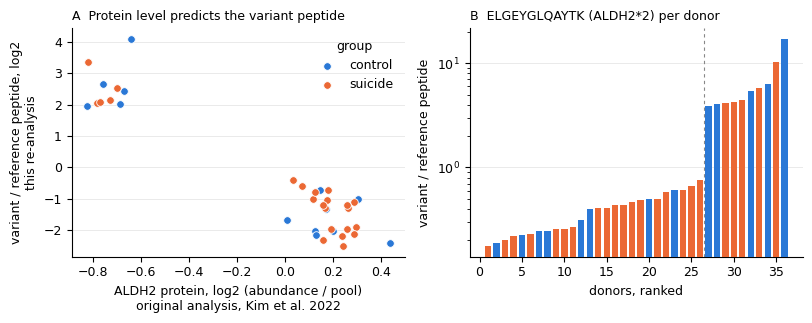

In [5]:
COL = {"control": "#2a78d6", "suicide": "#eb6834"}
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
L = pd.read_csv(RES / "two_cluster_scan.tsv", sep="\t")
auth = pd.read_excel(ROOT / "data_external" / "Kim2022_MOESM2_ESM.xlsx", sheet_name="Table S2", header=None, skiprows=3)
prot = np.log2(pd.to_numeric(auth[auth[3] == "ALDH2"].iloc[0, 16:52], errors="coerce").to_numpy(dtype=float))
d["protein_log2"] = prot                                          # same sample order as sample_map

fig, ax = plt.subplots(1, 2, figsize=(8.2, 3.3))
for g, sub in d.groupby("group"):
    ax[0].scatter(sub["protein_log2"], sub["log2_ratio"], s=30, color=COL[g], edgecolor="white", linewidth=0.6, label=g, zorder=3)
ax[0].set_xlabel("ALDH2 protein, log2 (abundance / pool)\noriginal analysis, Kim et al. 2022")
ax[0].set_ylabel("variant / reference peptide, log2\nthis re-analysis")
ax[0].set_title("A  Protein level predicts the variant peptide", fontsize=9, loc="left")
ax[0].legend(frameon=False, title="group", loc="upper right")
order = d.sort_values("log2_ratio").reset_index(drop=True)
ax[1].bar(range(1, 37), order["variant_to_reference"], color=[COL[g] for g in order["group"]], width=0.75, zorder=3)
ax[1].set_yscale("log"); ax[1].set_xlabel("donors, ranked"); ax[1].set_ylabel("variant / reference peptide")
ax[1].axvline(36 - order["carrier_by_peptide"].sum() + 0.5, color="#888888", lw=0.8, ls=(0, (3, 3)))
ax[1].set_title("B  ELGEYGLQAYTK (ALDH2*2) per donor", fontsize=9, loc="left")
for a in ax:
    a.grid(axis="y", color="#e6e6e6", lw=0.6); a.set_axisbelow(True)
fig.tight_layout(); fig.savefig(RES / "fig_ALDH2_variant_peptide.png", dpi=300); plt.show()

## Annotated spectrum of the variant peptide

The highest-scoring PSM of `ELGEYGLQAYTK` (TMT set 4, fraction 4, scan 33660; hyperscore 45.3, precursor purity 1.00) is shown with its fragment ions and its reporter ions.
The centroided scan was extracted from the raw file with ThermoRawFileParser 2.0.0 (`ThermoRawFileParser query -i <raw> -n 33660`) and is stored in `results/spectra/`.

All 22 singly charged b and y ions of the peptide are matched within 20 ppm. The base peak at m/z 230.17 is the TMT tag ion. The reporter ions of this one spectrum already single out the three carriers of TMT set 4.

In [6]:
import json
MASS = dict(G=57.02146, A=71.03711, S=87.03203, P=97.05276, V=99.06841, T=101.04768, C=160.03065, L=113.08406, I=113.08406, N=114.04293,
            D=115.02694, Q=128.05858, K=128.09496, E=129.04259, M=131.04049, H=137.05891, F=147.06841, R=156.10111, Y=163.06333, W=186.07931)
TMT, PROTON, WATER, TOL = 229.162932, 1.007276, 18.010565, 20e-6
spec = json.load(open(RES / "spectra" / "ALDH2_E504K_SET_4_frxn_4_scan_33660.json"))[0]
mz = np.array(spec["mzs"]); inten = np.array(spec["intensities"])
res = [MASS[a] for a in VARIANT]; res[-1] += TMT                 # TMT on the C-terminal lysine
ions = {}
for i in range(1, len(VARIANT)):
    ions[f"b{i}"] = TMT + sum(res[:i]) + PROTON                   # TMT on the peptide N-terminus
    ions[f"y{i}"] = sum(res[-i:]) + WATER + PROTON
matched = {}
for name, m in ions.items():
    j = np.argmin(np.abs(mz - m))
    if abs(mz[j] - m) / m <= TOL:
        matched[name] = j
frag = mz > 135
print(f"{len(matched)} of {len(ions)} singly charged b/y ions matched within 20 ppm;",
      f"they carry {100 * inten[list(matched.values())].sum() / inten[frag].sum():.0f}% of the fragment-ion intensity")
print("y ions:", " ".join(sorted((k for k in matched if k[0] == "y"), key=lambda s: int(s[1:]))))
print("b ions:", " ".join(sorted((k for k in matched if k[0] == "b"), key=lambda s: int(s[1:]))))

22 of 22 singly charged b/y ions matched within 20 ppm; they carry 32% of the fragment-ion intensity
y ions: y1 y2 y3 y4 y5 y6 y7 y8 y9 y10 y11
b ions: b1 b2 b3 b4 b5 b6 b7 b8 b9 b10 b11


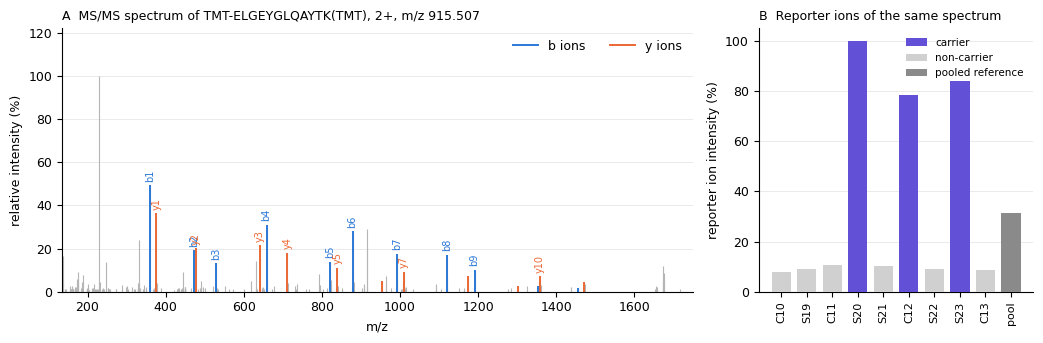

{'C10': 8, 'S19': 9, 'C11': 11, 'S20': 100, 'S21': 10, 'C12': 79, 'S22': 9, 'S23': 84, 'C13': 9, 'pool_SET4': 31}


In [7]:
REPORTER = {"126": 126.127726, "127N": 127.124761, "127C": 127.131081, "128N": 128.128116, "128C": 128.134436,
            "129N": 129.131471, "129C": 129.137790, "130N": 130.134825, "130C": 130.141145, "131N": 131.138180}
ann = dict(l.split() for l in (ROOT / "data_raw" / "SET_4" / "SET_4_annotation.txt").read_text().split("\n") if l.strip()) \
    if (ROOT / "data_raw" / "SET_4" / "SET_4_annotation.txt").exists() else \
    dict(zip(REPORTER, ["C10", "S19", "C11", "S20", "S21", "C12", "S22", "S23", "C13", "pool_SET4"]))
rep = {}
for ch, m in REPORTER.items():
    j = np.argmin(np.abs(mz - m)); rep[ch] = inten[j] if abs(mz[j] - m) / m <= TOL else 0.0
carriers = set(d.loc[d["carrier_by_peptide"], "sample"])

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.5), gridspec_kw={"width_ratios": [2.3, 1]})
a = ax[0]
a.vlines(mz[frag], 0, inten[frag] / inten[frag].max() * 100, color="#b5b5b5", lw=0.8, zorder=2)
CB, CY = "#2a78d6", "#eb6834"
top = sorted(matched, key=lambda k: -inten[matched[k]])
for k in matched:
    j = matched[k]; h = inten[j] / inten[frag].max() * 100; c = CB if k[0] == "b" else CY
    a.vlines(mz[j], 0, h, color=c, lw=1.4, zorder=3)
    if k in top[:16]:
        a.text(mz[j], h + 1.5, k, ha="center", va="bottom", fontsize=7, color=c, rotation=90)
a.set_xlim(135, 1750); a.set_ylim(0, 122); a.set_xlabel("m/z"); a.set_ylabel("relative intensity (%)")
a.set_title("A  MS/MS spectrum of TMT-ELGEYGLQAYTK(TMT), 2+, m/z 915.507", fontsize=9, loc="left")
a.plot([], [], color=CB, lw=1.4, label="b ions"); a.plot([], [], color=CY, lw=1.4, label="y ions"); a.legend(frameon=False, loc="upper right", ncol=2)
b = ax[1]
labels = [ann[ch] for ch in REPORTER]
vals = np.array([rep[ch] for ch in REPORTER]) / max(rep.values()) * 100
b.bar(range(10), vals, color=["#8a8a8a" if s.startswith("pool") else ("#6250d6" if s in carriers else "#d0d0d0") for s in labels], width=0.75, zorder=3)
b.set_xticks(range(10)); b.set_xticklabels([s.replace("pool_SET4", "pool") for s in labels], rotation=90, fontsize=8)
b.set_ylabel("reporter ion intensity (%)")
b.set_title("B  Reporter ions of the same spectrum", fontsize=9, loc="left")
for lab, c in [("carrier", "#6250d6"), ("non-carrier", "#d0d0d0"), ("pooled reference", "#8a8a8a")]:
    b.bar([0], [0], color=c, label=lab)
b.legend(frameon=False, fontsize=7.5, loc="upper right")
for x in ax:
    x.grid(axis="y", color="#e6e6e6", lw=0.6); x.set_axisbelow(True)
fig.tight_layout(); fig.savefig(RES / "fig_ALDH2_variant_spectrum.png", dpi=300); plt.show()
print({ann[ch]: round(v) for ch, v in zip(REPORTER, vals)})

## Result

- The 10 donors predicted to be carriers from protein abundance (notebook 02) are exactly the 10 donors with a high variant-to-reference peptide signal; the other 26 show only the background expected from co-isolation. The two groups do not overlap.
- Carrier frequency (10/36, 28%) is in the range reported for *ALDH2\*2* in East Asian populations, and carriers are not enriched in either group.
- The reference peptide is reduced in carriers, as expected when one allele no longer produces it and the variant subunit destabilises the enzyme.

## What this shows

Donor genotype at a pharmacogenetically relevant locus can be read from a public brain proteome with an open, documented workflow.
Zygosity cannot be assigned with confidence from MS2-level TMT data because of ratio compression.